# 第一部分：原论文行为复现与历史 HDDM 探索

[本部分 README](README_zh.md) · [第二部分](../02_reanalysis_2026/matching_h0_h3_results.ipynb)

## 研究问题与方法

先问 Good-self 行为优势是否能在公开数据和既有处理口径下复现，再问历史 HDDM 能支持多强的解释。本 Notebook 只读取已有表图，不重新分析原始数据、不运行 MCMC。Pilot 29 人；Confirm Matching 42 人、Categorization 41 人。图表保持历史样本/筛选口径。

## 诊断发现与方法调整

15 个选定 t 统计在预设容差内重现，并非所有论文统计都等价。Pilot Categorization RT 的条件列设置、omega/Bayes-factor 定义与 ex-Gaussian bootstrap 次数有差异，详见 README。历史模型与新 H0–H3 不同，不能直接比较其系数或诊断门槛。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '01_reproduction_2020').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the hu2020-ddm repository.')
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
def table(path):
    return pd.read_csv(ROOT / path)
def show(path, width=1000):
    display(Image(filename=str(ROOT / path), width=width))


## 结果：选定行为统计复核

In [2]:
checks = pd.concat([table('01_reproduction_2020/Output/behavior/'+s+'/'+s+'_key_reproduction_checks.csv').assign(study=s) for s in ['pilot','confirm']], ignore_index=True)
assert len(checks)==15 and checks.within_target_tolerance.all()
display(checks)

,outcome,contrast,paper_t,reproduced_t,abs_difference,within_target_tolerance,study
0,match_RT,GS_BS,-5.66900,-5.66944,0.00044,True,pilot
1,match_RT,GO_BO,-3.16400,-3.16370,0.00030,True,pilot
2,match_d,GS_BS,3.26000,3.26049,0.00049,True,pilot
3,categ_RT,GS_BS,-3.00000,-3.00456,0.00456,True,pilot
4,categ_ACC,GS_BS,3.59100,3.59075,0.00025,True,pilot
5,categ_ACC,GS_GO,3.43000,3.43222,0.00222,True,pilot
6,match_RT,GS_BS,-8.42000,-8.42343,0.00343,True,confirm
7,match_RT,GO_BO,-2.37000,-2.37541,0.00541,True,confirm
8,match_RT,GS_GO,-3.34000,-3.33717,0.00283,True,confirm
9,match_d,GS_BS,4.30000,4.30365,0.00365,True,confirm


### 图 I-1｜Pilot Matching：正确 RT 与历史 d′

Good-self 行为优势是待解释现象；历史 d′ 对非反应和极端比率的处理不同于第二部分合法选择口径。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

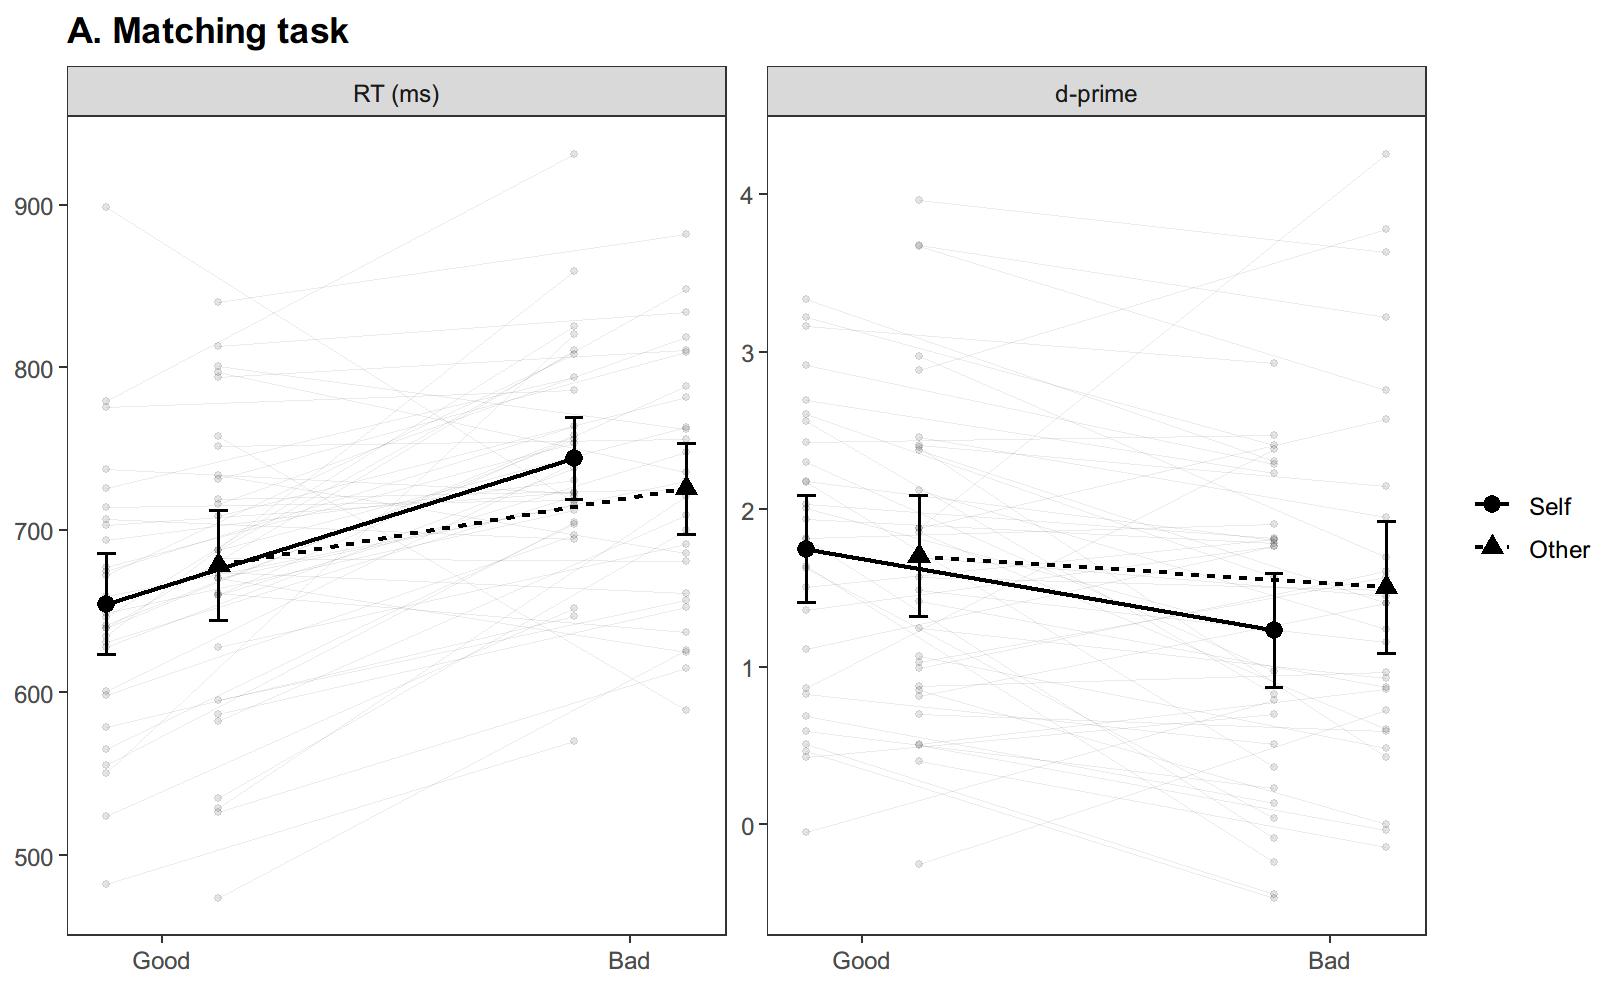

In [3]:
show('01_reproduction_2020/Output/behavior/pilot/figures/pilot_matching_behavior.png')

### 图 I-2｜Pilot Categorization

该图展示既有处理下的行为，不消除条件列分配引起的 ANOVA 可比性限制。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

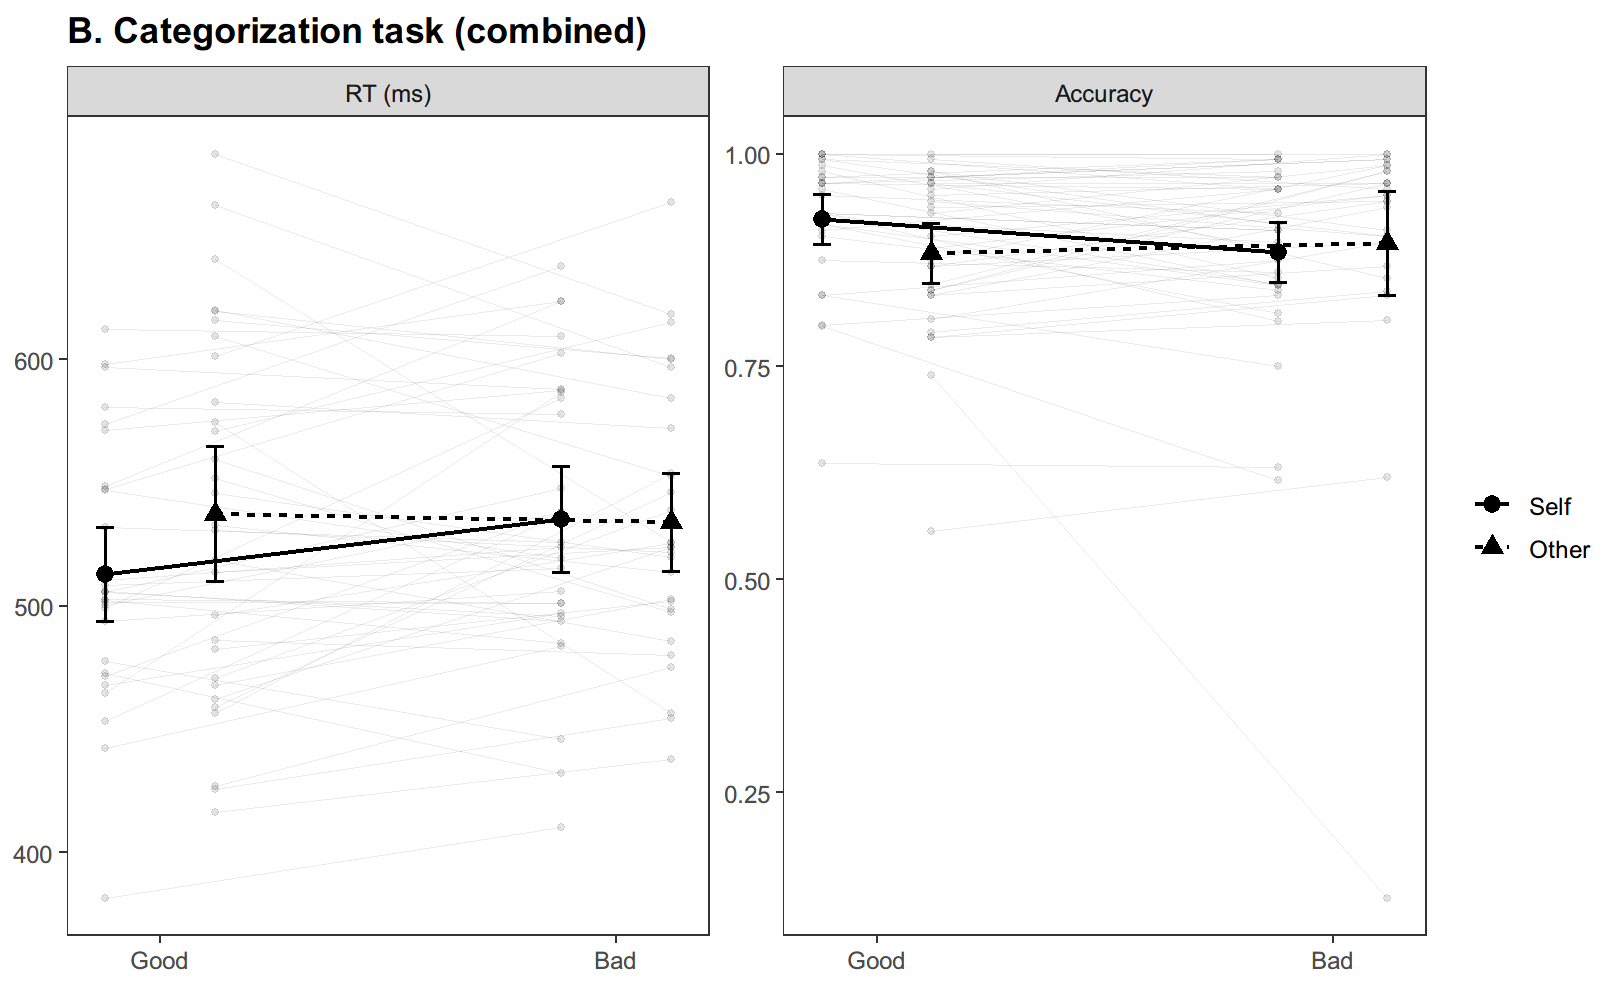

In [4]:
show('01_reproduction_2020/Output/behavior/pilot/figures/pilot_categorization_behavior.png')

### 图 I-3｜Confirm Matching

原行为筛选规则下的正确 RT 和 d′；不是全事件观察模型的预测图。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

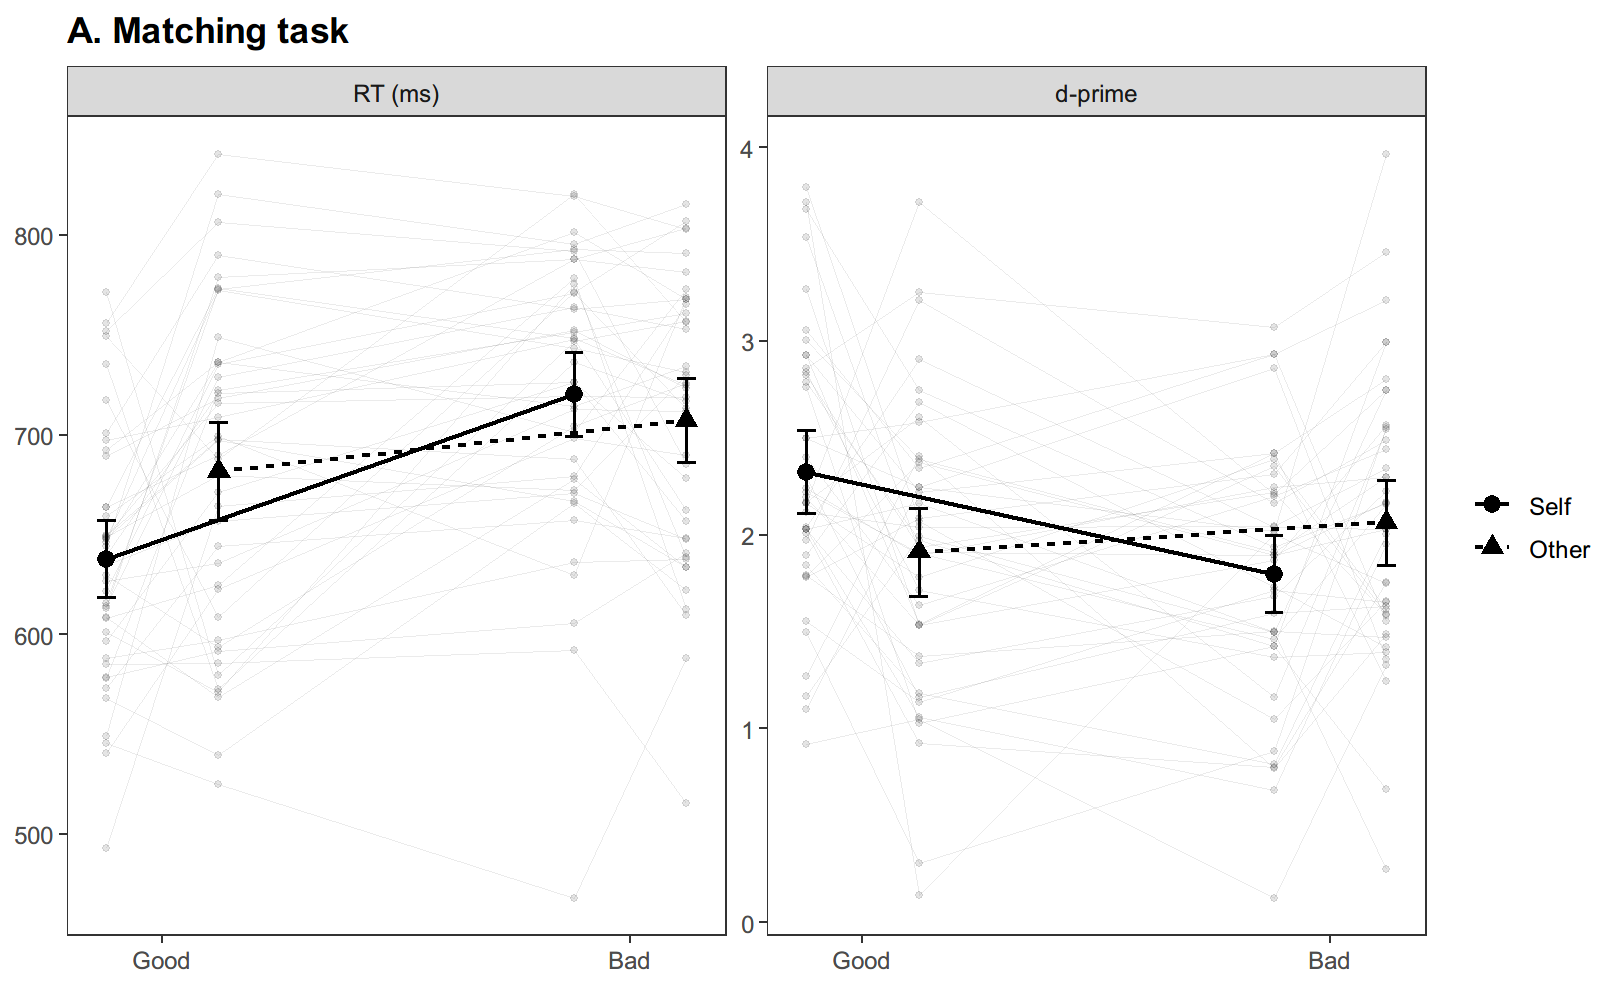

In [5]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_matching_behavior.png')

### 图 I-4｜Confirm Identity

Identity 行为结果与其 HDDM 是否收敛是不同问题。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

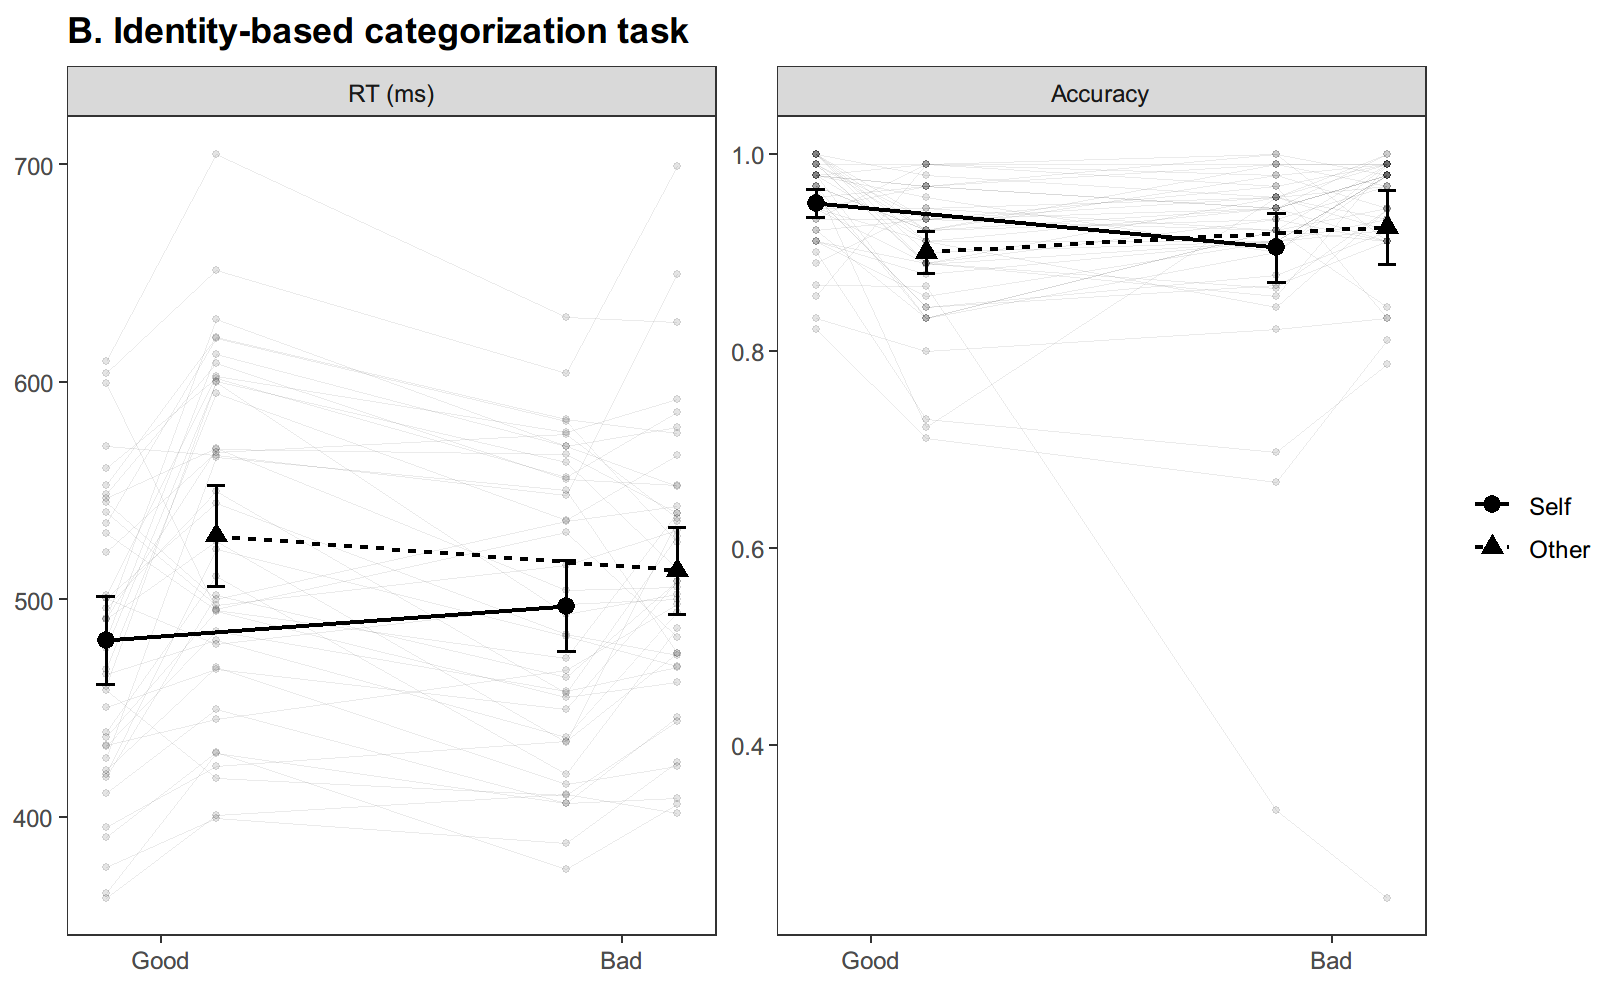

In [6]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_identity_behavior.png')

### 图 I-5｜Confirm Valence

历史 Figure 3C 引用已校正为 Valence 数据；不能从图形一致推断所有统计完全一致。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

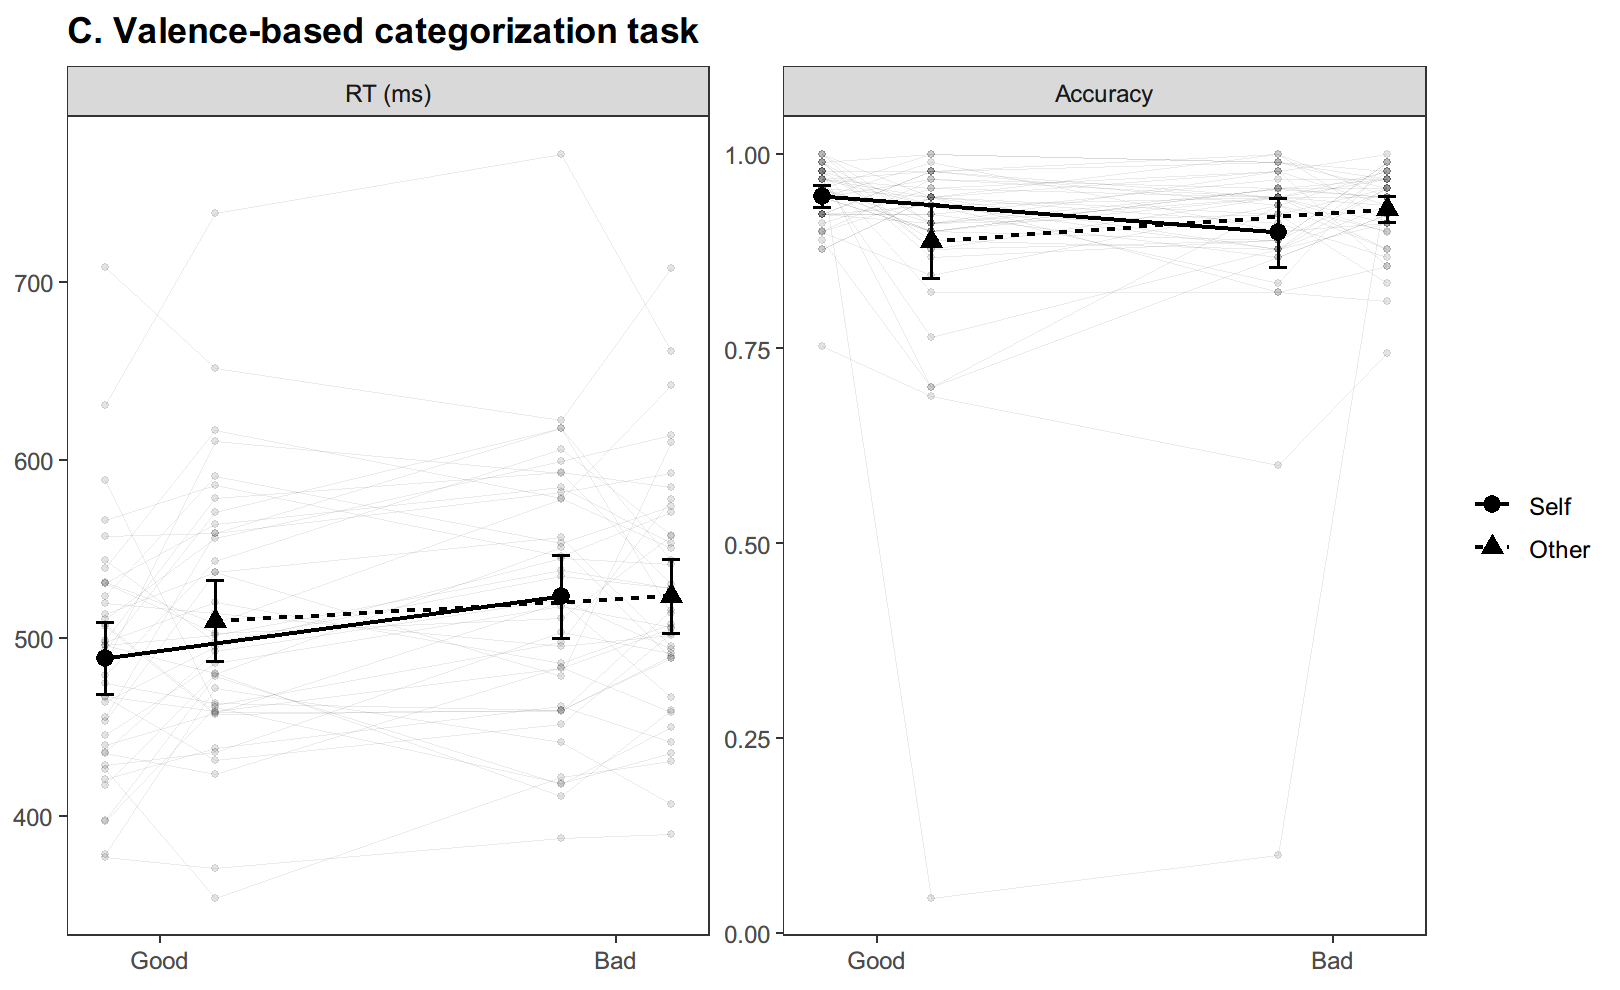

In [7]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_valence_behavior.png')

### 图 I-6｜历史 HDDM：原 Figure 4 漂移结果

使用已分发 r01 的 35 个群体参数，每个 9,000 样本；不是四链合并后验，不能代替完整数据库的诊断或 PPC。

模型标签 vtz/p0/r01 原样保留。此图展示漂移参数的后验密度曲线，不是误差条或可信区间图。

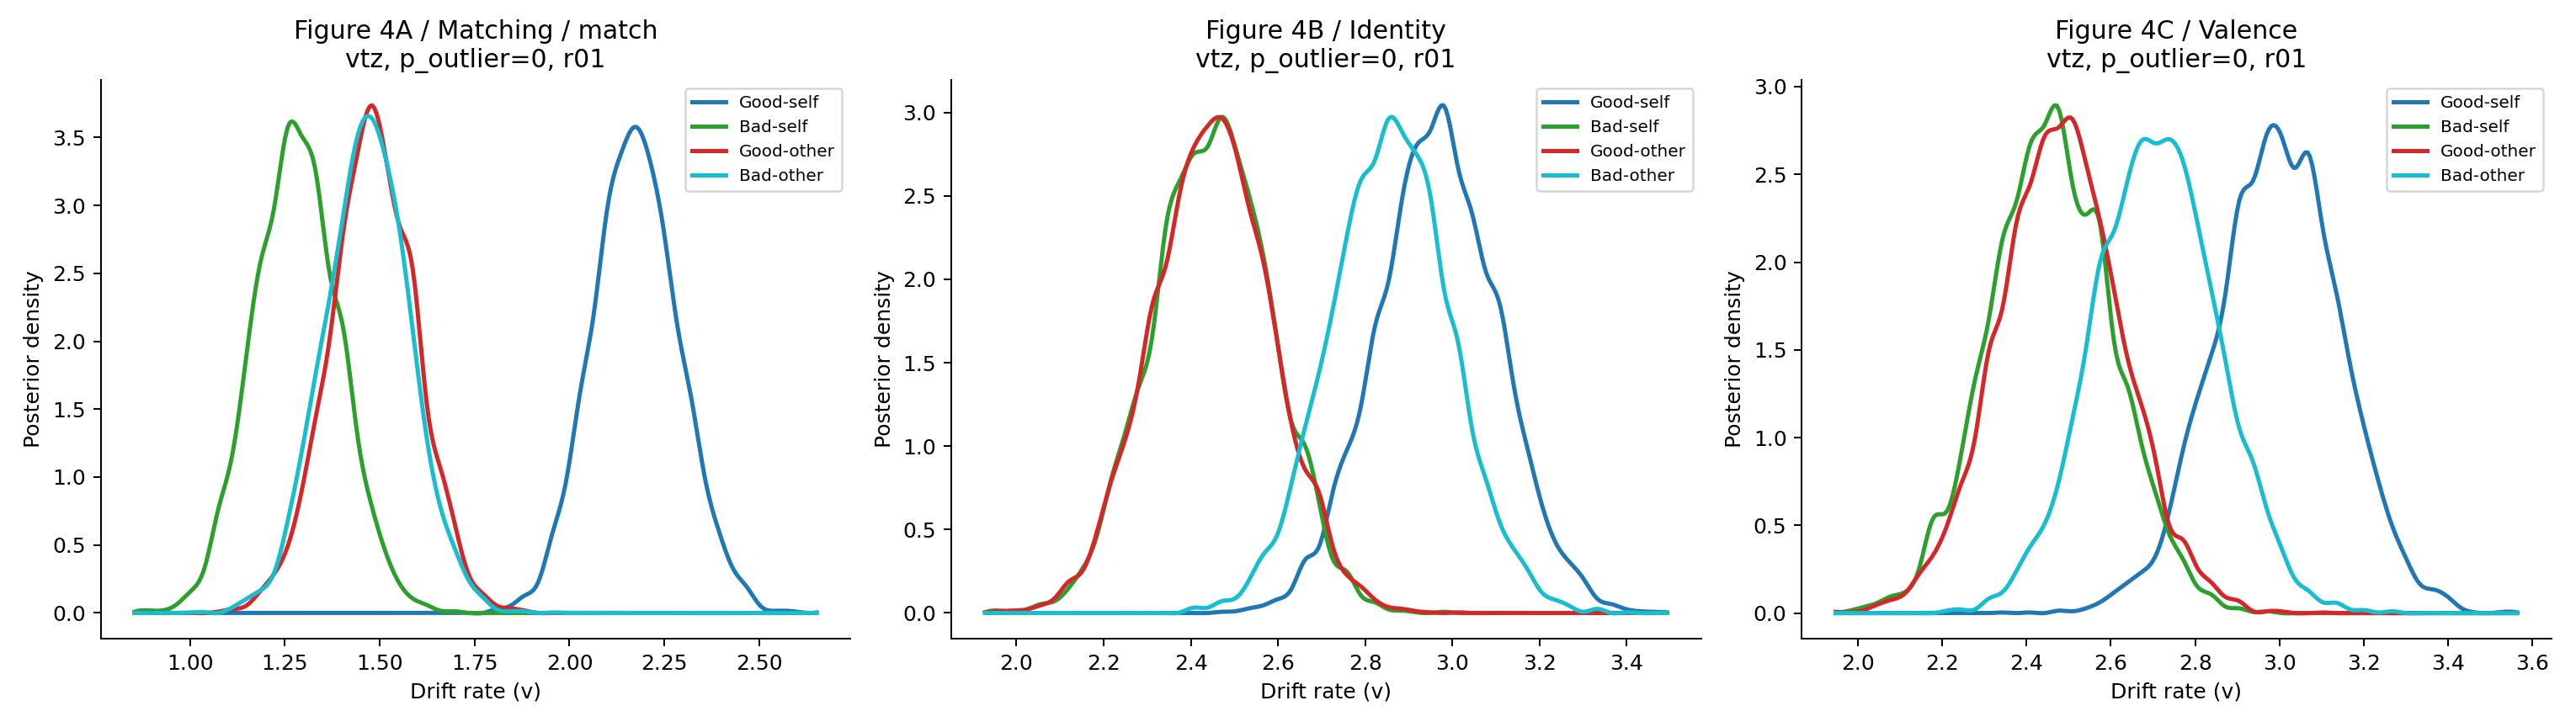

In [8]:
show('01_reproduction_2020/Output/figures/figure04_vtz_p0_r01_drift.png')

## 历史探索 → 限制 → 下一步

原论文模型的 Matching/Identity/Valence vtz p0 和 Identity vz p0 通过当时配置门槛；Identity vz p0.05 未通过，不合并其运行。Matching/Valence vz 只有一次运行，属描述性结果。补充 ex-Gaussian 和部分 Table S2/S3、Figure S3 尚不完整。

进一步的 [M0–M4 结果 Notebook](../02_reanalysis_2026/results.ipynb)保存漂移/偏置、轨迹与 PPC。Matching M4 主诊断通过，但预测慢尾和恢复有问题；Identity/Valence 长链仍未收敛。这促使我们核查响应窗口、标签关系与生成—估计一致性，进入 [H0–H3 再分析](../02_reanalysis_2026/matching_h0_h3_results.ipynb)。

行为复现支持现象，不能独立确定 v、dc 或 z 心理机制。第二部分可靠五折比较未完成；第三部分尚未正式分析。